In [1]:
import phidl
import phidl.geometry as pg
from phidl import quickplot as qp
import numpy as np
import os
from phidl import Device, Path
import phidl.path as pp
from scipy.constants import epsilon_0, mu_0
from scipy.special import ellipk
import phidl.routing as pr

In [2]:
def make_feedline_sub(pad_size,taper_len,feedline_len,feedline_width):
    
    pad = pg.taper(length=pad_size,width1=pad_size,width2=pad_size)
    taper = pg.taper(length=taper_len,width1=pad_size,width2=feedline_width)
    feedline = pg.taper(length=feedline_len,width1=feedline_width,width2=feedline_width)

    feedline_dev = phidl.Device("feedline")
    pad_ref1 = feedline_dev.add_ref(pad)
    taper_ref1 = feedline_dev.add_ref(taper)
    feedline_ref = feedline_dev.add_ref(feedline)
    taper_ref1.connect(1,destination=pad_ref1.ports[2])
    feedline_ref.connect(1,destination=taper_ref1.ports[2])
    taper_ref2 = feedline_dev.add_ref(taper)
    pad_ref2 = feedline_dev.add_ref(pad)
    taper_ref2.connect(2,destination=feedline_ref.ports[2])
    pad_ref2.connect(2,destination=taper_ref2.ports[1])
    feedline_dev.xmax = 0

    return feedline_dev

def make_feedline_contact(
    pad_size = 200,
    taper_len = 100,
    feedline_len = 0,
    feedline_width = 66,
    ground_gap = 2,
):
    """
    TODO: Add ports to couple resonator to!
    """
    feedline = make_feedline_sub(pad_size,taper_len,feedline_len,feedline_width)
    feedline.x = 0

    pad_size += 100
    feedline_width += 2*ground_gap

    feedline_outline = make_feedline_sub(pad_size,taper_len,feedline_len,feedline_width)
    feedline_outline.x = 0

    return feedline, feedline_outline

In [3]:
def make_feedline_contact(
    pad_size = 200,
    taper_len = 100,
    feedline_len = 0,
    feedline_width = 66,
    ground_gap = 2,
):
    """
    TODO: Add ports to couple resonator to!
    """
    feedline = make_feedline_sub(pad_size,taper_len,feedline_len,feedline_width)
    feedline.x = 0

    pad_size += 100
    feedline_width += 2*ground_gap

    feedline_outline = make_feedline_sub(pad_size,taper_len,feedline_len,feedline_width)
    feedline_outline.x = 0

    return feedline, feedline_outline

In [4]:
def make_coupling_elbow(
        coupling_length,
        turn_radius = 25,
        space = 100
    ):

    P = Path()
    P.append(pp.straight(coupling_length))
    direction = 1
    P.append(pp.euler(radius=turn_radius, angle=90*direction))
    P.append(pp.straight(space))

    return P

def make_coupling_hammerhead(
        coupling_length,
        coupling_width=5
    ):
    hammerhead = pg.rectangle(size=(coupling_length,coupling_width))
    hammerhead.add_port(1,midpoint=(coupling_length/2,coupling_width),orientation=90)
    return hammerhead

In [5]:
def calculate_segment_length(
    L_len=400,
    radius=200
):
    P = Path()
    direction = -1
    P.append(pp.straight(2*radius))
    P.append(pp.straight(L_len))
    P.append(pp.arc(radius=radius, angle=-180*direction))
    P.append(pp.straight(L_len))
    direction *= -1
    P.append(pp.arc(radius=radius, angle=-90*direction))
    return P.length()

In [61]:
def make_lamda2_res_meander(
    L_len=150,
    radius=150,
    width=2,
    center_pin_length=7000,
    center_pin_gap = 60,
    coupling_length = 20,
    coupling_width=5,
    space=100,
    hammerhead_gap=2
):

    P = Path()
    direction = -1
    P.append(pp.arc(radius=radius, angle=90 * direction))
    P.append(pp.straight(L_len))
    P.append(pp.arc(radius=radius, angle=-180 * direction))
    P.append(pp.straight(L_len))
    add_length = calculate_segment_length(L_len=L_len,radius=radius)
    total_length = P.length()
    while total_length < (center_pin_length-add_length):

        P.append(pp.straight(2*radius))
        P.append(pp.straight(L_len))
        P.append(pp.arc(radius=radius, angle=180 * direction))
        P.append(pp.straight(L_len))
        direction *= -1
        total_length = P.length()

    P.append(pp.arc(radius=radius, angle=90 * direction))
    total_length = P.length()

    remaining_len = center_pin_length - P.length()
    if remaining_len < 0:
        print("ERROR! NEGATIVE LENGTH!")

    P = pp.straight(remaining_len/2).append(P)
    P = P.append(pp.straight(remaining_len/2))

    print(P.length())

    D = Device('meander')
    X = phidl.CrossSection()
    X.add(width = width, ports = (1,2))

    D << P.extrude(X)
    D.add_port(D.references[0].ports[1])
    D.add_port(D.references[0].ports[2])

    hammerhead = pg.rectangle(size=(coupling_length,coupling_width))
    hammerhead.add_port(1,midpoint=(coupling_length/2,coupling_width),orientation=90)
    hammerhead.add_port(2,midpoint=(coupling_length/2,0),orientation=-90)

    coupled_resonator = phidl.Device('coupled_resonator')
    resonator_ref = coupled_resonator.add_ref(D)
    hh_ref1 = coupled_resonator.add_ref(hammerhead)
    hh_ref1.connect(2,resonator_ref.ports[1])
    hh_ref2 = coupled_resonator.add_ref(hammerhead)
    hh_ref2.connect(1,resonator_ref.ports[2])
    coupled_resonator = pg.union(coupled_resonator, by_layer=False, precision=1e-6, join_first=True, max_points=0, layer=0)

    coupled_resonator.add_port(hh_ref1.ports[1])
    coupled_resonator.add_port(hh_ref2.ports[2])

    D = Device('meander')
    X = phidl.CrossSection()
    X.add(width = width+2*center_pin_gap, ports = (1,2))
    D << P.extrude(X)
    D.add_port(D.references[0].ports[1])
    D.add_port(D.references[0].ports[2])

    hammerhead = pg.rectangle(size=(2*center_pin_gap+width,coupling_width+hammerhead_gap))
    hammerhead.add_port(1,midpoint=((2*center_pin_gap+width)/2,coupling_width+hammerhead_gap),orientation=90)
    hammerhead.add_port(2,midpoint=((2*center_pin_gap+width)/2,0),orientation=-90)
    
    coupled_resonator_outline = phidl.Device('outline_coupled_resonator')
    ref_D_outline = coupled_resonator_outline.add_ref(D)
    hh_ref1 = coupled_resonator_outline.add_ref(hammerhead)
    hh_ref1.connect(2,ref_D_outline.ports[1])
    hh_ref2 = coupled_resonator_outline.add_ref(hammerhead)
    hh_ref2.connect(1,ref_D_outline.ports[2])

    coupled_resonator_outline.add_port(hh_ref1.ports[1])
    coupled_resonator_outline.add_port(hh_ref2.ports[2])
    
    coupled_resonator.rotate(90)
    coupled_resonator_outline.rotate(90)

    return coupled_resonator, coupled_resonator_outline

In [62]:
def make_lamda4_res_meander(
    L_len=150,
    radius=150,
    width=2,
    center_pin_length=7000,
    center_pin_gap = 60,
    coupling_length = 20,
    coupling_width=5,
    space=100,
    hammerhead_gap=2
):

    P = Path()
    direction = -1
    P.append(pp.arc(radius=radius, angle=90 * direction))
    P.append(pp.straight(L_len))
    P.append(pp.arc(radius=radius, angle=-180 * direction))
    P.append(pp.straight(L_len))
    add_length = calculate_segment_length(L_len=L_len,radius=radius)
    total_length = P.length()
    while total_length < (center_pin_length-add_length):

        P.append(pp.straight(2*radius))
        P.append(pp.straight(L_len))
        P.append(pp.arc(radius=radius, angle=180 * direction))
        P.append(pp.straight(L_len))
        direction *= -1
        total_length = P.length()

    P.append(pp.arc(radius=radius, angle=90 * direction))
    total_length = P.length()

    remaining_len = center_pin_length - P.length()
    if remaining_len < 0:
        print("ERROR! NEGATIVE LENGTH!")

    P = pp.straight(remaining_len/2).append(P)
    P = P.append(pp.straight(remaining_len/2))

    print(P.length())

    D = Device('meander')
    X = phidl.CrossSection()
    X.add(width = width, ports = (1,2))

    D << P.extrude(X)
    D.add_port(D.references[0].ports[1])
    D.add_port(D.references[0].ports[2])

    if coupling_length < width:
            coupling_length = width

    hammerhead = pg.rectangle(size=(coupling_length,coupling_width))
    hammerhead.add_port(1,midpoint=(coupling_length/2,coupling_width),orientation=90)
    hammerhead.add_port(2,midpoint=(coupling_length/2,0),orientation=-90)

    coupled_resonator = phidl.Device('coupled_resonator')
    resonator_ref = coupled_resonator.add_ref(D)
    hh_ref1 = coupled_resonator.add_ref(hammerhead)
    hh_ref1.connect(2,resonator_ref.ports[1])
    coupled_resonator = pg.union(coupled_resonator, by_layer=False, precision=1e-6, join_first=True, max_points=0, layer=0)

    coupled_resonator.add_port(hh_ref1.ports[1])

    D = Device('meander')
    X = phidl.CrossSection()
    X.add(width = width+2*center_pin_gap, ports = (1,2))
    D << P.extrude(X)
    D.add_port(D.references[0].ports[1])
    D.add_port(D.references[0].ports[2])

    hammerhead = pg.rectangle(size=(2*center_pin_gap+width,coupling_width+hammerhead_gap))
    hammerhead.add_port(1,midpoint=((2*center_pin_gap+width)/2,coupling_width+hammerhead_gap),orientation=90)
    hammerhead.add_port(2,midpoint=((2*center_pin_gap+width)/2,0),orientation=-90)
    
    coupled_resonator_outline = phidl.Device('outline_coupled_resonator')
    ref_D_outline = coupled_resonator_outline.add_ref(D)
    hh_ref1 = coupled_resonator_outline.add_ref(hammerhead)
    hh_ref1.connect(2,ref_D_outline.ports[1])

    coupled_resonator_outline.add_port(hh_ref1.ports[1])
    
    coupled_resonator.rotate(90)
    coupled_resonator_outline.rotate(90)

    return coupled_resonator, coupled_resonator_outline

In [8]:
hammerhead_gap = 50
width = 20
center_pin_gap = 60
center_pin_length = 4000
coupling_length = 20
common_params = dict(
    L_len=350,
    radius=200,
    coupling_width=5
)
res, outline = make_lamda4_res_meander(hammerhead_gap=hammerhead_gap,width=width, center_pin_gap=center_pin_gap, center_pin_length=center_pin_length, coupling_length = coupling_length,**common_params)

4000.0


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


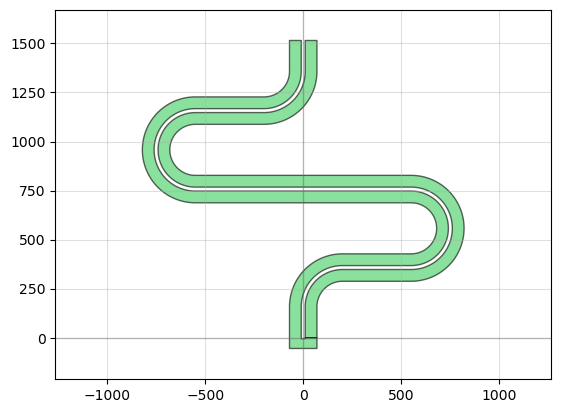

In [9]:
diff = pg.boolean(outline,res,operation='A-B')
qp(diff)

In [10]:
def smooth_device(r,smoothing_radius=2):
    r_round = phidl.Device("round_r")
    for port in r.ports.values():
        r_round.add_port(port)
    dev = pg.union(r, precision=1e-6, layer=0)   # instead of boolean with B=None
    dev.flatten()
    for ps in dev.polygons:
        ps.fillet(radius=smoothing_radius)
        for pts in ps.polygons:          # a PolygonSet can hold several polygons
            r_round.add_polygon(pts, layer=0)
    return r_round

### Define resonators!

In [109]:
# resonator_params = [(180,50,100,8000,50),(155,45,85,8250,50),(130,40,70,8500,50),(105,35,55,8750,50),(80,30,40,9000,50)]
# hammerhead_gaps = [180,155,130,105,80]
# resonator_params = [(30,18,8,2750,18),(50,22,16,2875,22),(60,26,24,2900,26),(90,30,32,5250,30),(120,34,40,5000,34)]
# hammerhead_gaps = [30,50,60,90,120]

lambda_4_resonator_params = [(20,18,8,3000),(65,28,28,3600),(105,36,48,3750),(40,18,8,1800),(210,48,88,2650)]
lambda_2_resonator_params = [(135,42,68,7600),(175,48,88,7550)]

common_params = dict(
    L_len=150,
    radius=200,
    coupling_width=1
)

resonators = []
outlines = []
hammerhead_gaps = []
for (hammerhead_gap,width,center_pin_gap,center_pin_length) in lambda_4_resonator_params:
    res, outline = make_lamda4_res_meander(hammerhead_gap=hammerhead_gap,width=width, center_pin_gap=center_pin_gap, center_pin_length=center_pin_length, coupling_length = width,**common_params)
    resonators.append(res)
    outlines.append(outline)
    hammerhead_gaps.append(hammerhead_gap)

for (hammerhead_gap,width,center_pin_gap,center_pin_length) in lambda_2_resonator_params:
    res, outline = make_lamda2_res_meander(hammerhead_gap=hammerhead_gap,width=width, center_pin_gap=center_pin_gap, center_pin_length=center_pin_length, coupling_length = width,**common_params)
    resonators.append(res)
    outlines.append(outline)
    hammerhead_gaps.append(hammerhead_gap)

pad_size = 250
taper_len = 100
feedline_len = 7000
feedline_width = 80
ground_gap = 10

feedline, feedline_outline = make_feedline_contact(    
    pad_size = pad_size,
    taper_len = taper_len,
    feedline_len = feedline_len,
    feedline_width = feedline_width,
    ground_gap = ground_gap
    )

feedline.add_port(0,midpoint=(-4*feedline_len/10,feedline_width/2),orientation=90)
feedline.add_port(1,midpoint=(-feedline_len/10,feedline_width/2),orientation=90)
feedline.add_port(2,midpoint=(feedline_len/10,feedline_width/2),orientation=90)
feedline.add_port(3,midpoint=(4*feedline_len/10,feedline_width/2),orientation=90)
feedline.add_port(4,midpoint=(-feedline_len/4,-feedline_width/2),orientation=-90)
feedline.add_port(5,midpoint=(0,-feedline_width/2),orientation=-90)
feedline.add_port(6,midpoint=(feedline_len/4,-feedline_width/2),orientation=-90)

3000.0000000000005
3600.0
3750.0
1800.0
2650.0
7600.0
7550.0


Port (name 6, midpoint [1750.  -40.], width 1, orientation 270)

In [110]:
# Define vortex pinning lattice.
sq = pg.rectangle(size = (5,5))
device_list = []
i = int(10e3//100)
j = int(10e3//100)

for obj in range(i*j):
    device_list.append(sq)

# lattice_device = phidl.geometry.grid(
#     device_list=[device_list],
#     spacing=(100, 100),     # X and Y distance between elements
#     separation=True,    # True = fixed gap size; False = even center-to-center spacing
#     shape=(i,j)        # Dimensions of the grid grid (columns, rows)
# )

groundplane = pg.rectangle(size=(10000,10000))
# groundplane = pg.boolean(groundplane,lattice_device,operation='A-B')

In [111]:
current, current_outline = make_feedline_contact(    
    pad_size = 250,
    taper_len = 50,
    feedline_len = 800,
    feedline_width = 100,
    ground_gap = 25
    )

voltage, voltage_outline = make_feedline_contact(    
    pad_size = 250,
    taper_len = 50,
    feedline_len = 400,
    feedline_width = 10,
    ground_gap = 25
    )

def make_hallbar(current,voltage1):

    hallbar = phidl.Device('hallbar')
    current_ref = hallbar.add_ref(current)
    current_ref.x=0

    voltage_ref1 = hallbar.add_ref(voltage1)
    voltage_ref1.rotate(90)
    voltage_ref1.y = 0
    voltage_ref1.x = -750/3

    voltage_ref2 = hallbar.add_ref(voltage1)
    voltage_ref2.rotate(90)
    voltage_ref2.y = 0
    voltage_ref2.x = 750/3

    return hallbar

In [112]:
def make_nanowire(
    L_len=300,
    radius=150,
    width=2,
    center_pin_length=7000,
    center_pin_gap = 60,
):

    P = Path()
    direction = -1
    P.append(pp.arc(radius=radius, angle=90 * direction))
    P.append(pp.straight(L_len))
    P.append(pp.arc(radius=radius, angle=-180 * direction))
    P.append(pp.straight(L_len))
    add_length = calculate_segment_length(L_len=L_len,radius=radius)
    total_length = P.length()
    while total_length < (center_pin_length-add_length):

        P.append(pp.straight(2*radius))
        P.append(pp.straight(L_len))
        P.append(pp.arc(radius=radius, angle=180 * direction))
        P.append(pp.straight(L_len))
        direction *= -1
        total_length = P.length()

    P.append(pp.arc(radius=radius, angle=90 * direction))
    total_length = P.length()

    remaining_len = center_pin_length - P.length()
    if remaining_len < 0:
        print("ERROR! NEGATIVE LENGTH!")

    P = pp.straight(remaining_len/2).append(P)
    P = P.append(pp.straight(remaining_len/2))

    print(P.length())

    D = Device('meander')
    X = phidl.CrossSection()
    X.add(width = width, ports = (1,2))

    D << P.extrude(X)
    D.add_port(D.references[0].ports[1])
    D.add_port(D.references[0].ports[2])

    coupled_nanowire = D

    D = Device('meander')
    X = phidl.CrossSection()
    X.add(width = width+2*center_pin_gap, ports = (1,2))
    D << P.extrude(X)
    D.add_port(D.references[0].ports[1])
    D.add_port(D.references[0].ports[2])

    coupled_nanowire_outline = D

    return coupled_nanowire, coupled_nanowire_outline

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


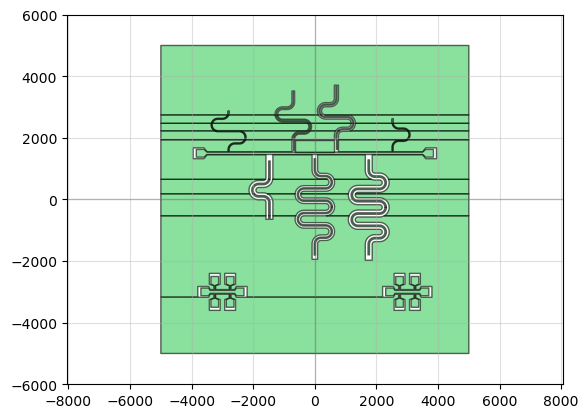

'110426_inv_nbn_res_chip.gds'

In [113]:
smooth = False

chip_layout = phidl.Device('chip_layout')
groundplane_ref = chip_layout.add_ref(groundplane)
groundplane_ref.x=0
groundplane_ref.y=0

if smooth:
    feedline = smooth_device(feedline)
    feedline_outline = smooth_device(feedline_outline)
    resonators = [smooth_device(res) for res in resonators]
    outlines = [smooth_device(outline) for outline in outlines]

# Subtract the ground plane gaps.
feedline_ref = chip_layout.add_ref(feedline)
feedline_outline_ref = chip_layout.add_ref(feedline_outline)

feedline_ref.y = 1500
feedline_outline_ref.y = 1500

# Add feedline.
chip_layout = pg.boolean(chip_layout,feedline_outline_ref,operation='A-B')
chip_layout = pg.boolean(chip_layout,feedline_ref,operation='A+B')

for i in [0,1,2,3]:
    res = resonators[i]
    res_outline = outlines[i]
    hammerhead_gap = hammerhead_gaps[i]
    res_ref = chip_layout.add_ref(res)
    res_outline_ref = chip_layout.add_ref(res_outline)
    port = feedline_ref.ports[i]

    res_outline_ref.x = port.midpoint[0]
    res_outline_ref.ymin = port.midpoint[1] 

    res_ref.x = port.midpoint[0]
    res_ref.ymin = port.midpoint[1] + hammerhead_gap
    # res_ref.move(origin=res_ref.ports[1], destination=[port.midpoint[0],port.midpoint[1] + hammerhead_gap])
    # res_outline_ref.move(origin=res_ref_outline.ports[1], destination=[port.midpoint[0],port.midpoint[1] + hammerhead_gap])

    chip_layout = pg.boolean(chip_layout,res_outline_ref,operation='A-B')
    chip_layout = pg.boolean(chip_layout,res_ref,operation='A+B')

for i in [4]:
    res = resonators[i]
    res_outline = outlines[i]
    hammerhead_gap = hammerhead_gaps[i]

    res.rotate(180)
    res_outline.rotate(180)
    res_ref = chip_layout.add_ref(res)
    res_outline_ref = chip_layout.add_ref(res_outline)
    port = feedline_ref.ports[i]

    res_outline_ref.x = port.midpoint[0]
    res_outline_ref.ymax = port.midpoint[1] 

    res_ref.x = port.midpoint[0]
    res_ref.ymax = port.midpoint[1] - hammerhead_gap

    chip_layout = pg.boolean(chip_layout,res_outline_ref,operation='A-B')
    chip_layout = pg.boolean(chip_layout,res_ref,operation='A+B')

for i in [5,6]:
    res = resonators[i]
    res_outline = outlines[i]
    hammerhead_gap = hammerhead_gaps[i]
    res_ref = chip_layout.add_ref(res)
    res_outline_ref = chip_layout.add_ref(res_outline)
    port = feedline_ref.ports[i]

    res_outline_ref.x = port.midpoint[0]
    res_outline_ref.ymax = port.midpoint[1] 

    res_ref.x = port.midpoint[0]
    res_ref.ymax = port.midpoint[1] - hammerhead_gap

    chip_layout = pg.boolean(chip_layout,res_outline_ref,operation='A-B')
    chip_layout = pg.boolean(chip_layout,res_ref,operation='A+B')

for (x,y) in [(-3000,-3000),(3000,-3000)]:

    hallbar = make_hallbar(current,voltage)
    hallbar_outline = make_hallbar(current_outline,voltage_outline)
    # hallbar.rotate(90)
    # hallbar_outline.rotate(90)

    hallbar_ref = chip_layout.add_ref(hallbar)
    hallbar_outline_ref = chip_layout.add_ref(hallbar_outline)

    hallbar_ref.x = x
    hallbar_ref.y = y
    hallbar_outline_ref.x = x
    hallbar_outline_ref.y = y

    chip_layout = pg.boolean(chip_layout,hallbar_outline_ref,operation='A-B')
    chip_layout = pg.boolean(chip_layout,hallbar_ref,operation='A+B')

qp(chip_layout)
chip_layout.write_gds('110426_inv_nbn_res_chip.gds')

In [114]:
nanowire, nanowire_outline = make_nanowire(
    L_len=100,
    radius=25,
    width=1,
    center_pin_length=900,
    center_pin_gap = 100
)

nanowire.x = 0
nanowire.y = -3000
nanowire_outline.x = 0
nanowire_outline.y = -3000

diff = pg.boolean(nanowire_outline,nanowire,operation='A-B')
diff.remap_layers({0:2})

900.0


Device (name "boolean" (uid 2133), ports [], aliases [], 2 polygons, 0 references)

In [115]:
negative_mask = pg.invert(chip_layout,border=0,layer=1)

# Add in centering groundplane.
ground_plane_ref = negative_mask.add_ref(groundplane)
ground_plane_ref.x=0
ground_plane_ref.y=0

# Define markers.
marker = pg.rectangle(size = (20,20),layer=1)
marker.x=0
marker.y=0

center_marker = pg.rectangle(size = (5,5),layer=1)
marker.x=0
marker.y=0

# Add markers.
marker_locs = [(3000,1200)]
for marker_loc in marker_locs:
    for xmag in [-1,1]:
        for ymag in [-1,-.5,0,.5]:
            xloc = xmag*marker_loc[0]
            yloc = ymag*marker_loc[1]
            marker_ref = negative_mask.add_ref(marker)
            center_marker_ref = negative_mask.add_ref(center_marker)
            marker_ref.x = xloc
            marker_ref.y = yloc
            center_marker_ref.x = xloc
            center_marker_ref.y = yloc

In [102]:
negative_mask.add_ref(diff)

DeviceReference (parent Device "boolean", ports [], origin (0, 0), rotation 0, x_reflection False)

In [116]:
negative_mask.write_gds('110426_nbn_res_chip.gds')

'110426_nbn_res_chip.gds'

In [19]:
def make_lamda2_res_straight(
    radius=50,
    width=2,
    center_pin_length=3500,
    center_pin_gap = 60,
    coupling_length = 100,
    coupling_width=5,
    hammerhead_gap=2
):

    P = Path()
    P.append(pp.straight(center_pin_length))

    print('total length',P.length())

    D = Device('meander')
    X = phidl.CrossSection()
    X.add(width = width, ports = (1,2))

    D << P.extrude(X)
    D.add_port(D.references[0].ports[1])
    D.add_port(D.references[0].ports[2])

    coupling_length = width

    hammerhead = pg.rectangle(size=(coupling_length,coupling_width))
    hammerhead.add_port(1,midpoint=(coupling_length/2,coupling_width),orientation=90)
    hammerhead.add_port(2,midpoint=(coupling_length/2,0),orientation=-90)

    coupled_resonator = phidl.Device('coupled_resonator')
    resonator_ref = coupled_resonator.add_ref(D)
    hh_ref1 = coupled_resonator.add_ref(hammerhead)
    hh_ref1.connect(2,resonator_ref.ports[1])
    hh_ref2 = coupled_resonator.add_ref(hammerhead)
    hh_ref2.connect(1,resonator_ref.ports[2])
    coupled_resonator = pg.union(coupled_resonator, by_layer=False, precision=1e-6, join_first=True, max_points=0, layer=0)

    coupled_resonator.add_port(hh_ref1.ports[1])
    coupled_resonator.add_port(hh_ref2.ports[2])

    D = Device('meander')
    X = phidl.CrossSection()
    X.add(width = width+2*center_pin_gap, ports = (1,2))
    D << P.extrude(X)
    D.add_port(D.references[0].ports[1])
    D.add_port(D.references[0].ports[2])

    hammerhead = pg.rectangle(size=(2*center_pin_gap+width,coupling_width+hammerhead_gap))
    hammerhead.add_port(1,midpoint=((2*center_pin_gap+width)/2,coupling_width+hammerhead_gap),orientation=90)
    hammerhead.add_port(2,midpoint=((2*center_pin_gap+width)/2,0),orientation=-90)
    
    coupled_resonator_outline = phidl.Device('outline_coupled_resonator')
    ref_D_outline = coupled_resonator_outline.add_ref(D)
    hh_ref1 = coupled_resonator_outline.add_ref(hammerhead)
    hh_ref1.connect(2,ref_D_outline.ports[1])
    hh_ref2 = coupled_resonator_outline.add_ref(hammerhead)
    hh_ref2.connect(1,ref_D_outline.ports[2])

    coupled_resonator_outline.add_port(hh_ref1.ports[1])
    coupled_resonator_outline.add_port(hh_ref2.ports[2])
    
    coupled_resonator.rotate(90)
    coupled_resonator_outline.rotate(90)

    return coupled_resonator, coupled_resonator_outline

In [20]:
def make_lamda4_res_straight(
    radius=50,
    width=2,
    center_pin_length=3500,
    center_pin_gap = 60,
    coupling_length = 100,
    coupling_width=5,
    hammerhead_gap=2
):

    P = Path()
    P.append(pp.straight(center_pin_length))

    print('total length',P.length())

    D = Device('meander')
    X = phidl.CrossSection()
    X.add(width = width, ports = (1,2))

    D << P.extrude(X)
    D.add_port(D.references[0].ports[1])
    D.add_port(D.references[0].ports[2])

    # coupling_length = width

    hammerhead = pg.rectangle(size=(coupling_length,coupling_width))
    hammerhead.add_port(1,midpoint=(coupling_length/2,coupling_width),orientation=90)
    hammerhead.add_port(2,midpoint=(coupling_length/2,0),orientation=-90)

    coupled_resonator = phidl.Device('coupled_resonator')
    resonator_ref = coupled_resonator.add_ref(D)
    hh_ref1 = coupled_resonator.add_ref(hammerhead)
    hh_ref1.connect(2,resonator_ref.ports[1])
    coupled_resonator = pg.union(coupled_resonator, by_layer=False, precision=1e-6, join_first=True, max_points=0, layer=0)

    coupled_resonator.add_port(hh_ref1.ports[1])

    D = Device('meander')
    X = phidl.CrossSection()
    X.add(width = width+2*center_pin_gap, ports = (1,2))
    D << P.extrude(X)
    D.add_port(D.references[0].ports[1])
    D.add_port(D.references[0].ports[2])

    hammerhead = pg.rectangle(size=(2*center_pin_gap+width,coupling_width+hammerhead_gap))
    hammerhead.add_port(1,midpoint=((2*center_pin_gap+width)/2,coupling_width+hammerhead_gap),orientation=90)
    hammerhead.add_port(2,midpoint=((2*center_pin_gap+width)/2,0),orientation=-90)
    
    coupled_resonator_outline = phidl.Device('outline_coupled_resonator')
    ref_D_outline = coupled_resonator_outline.add_ref(D)
    hh_ref1 = coupled_resonator_outline.add_ref(hammerhead)
    hh_ref1.connect(2,ref_D_outline.ports[1])

    coupled_resonator_outline.add_port(hh_ref1.ports[1])
    
    coupled_resonator.rotate(90)
    coupled_resonator_outline.rotate(90)

    return coupled_resonator, coupled_resonator_outline

In [21]:
# # Groundplane with vortex traps.
groundplane = pg.rectangle(size=(10e3,10e3))

# # Define vortex pinning lattice.
# sq = pg.rectangle(size = (10,10))
# device_list = []
# i = int(10e3//100)
# j = int(10e3//100)

# for obj in range(i*j):
#     device_list.append(sq)

# lattice_device = phidl.geometry.grid(
#     device_list=[device_list],
#     spacing=(100, 100),     # X and Y distance between elements
#     separation=True,    # True = fixed gap size; False = even center-to-center spacing
#     shape=(i,j)        # Dimensions of the grid grid (columns, rows)
# )

# groundplane = pg.boolean(groundplane,lattice_device,operation='A-B')
# groundplane.write_gds("groundplane.gds")

groundplane_ref = chip_layout.add_ref(groundplane)
groundplane_ref.x=0
groundplane_ref.y=0

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


total length 3750.0


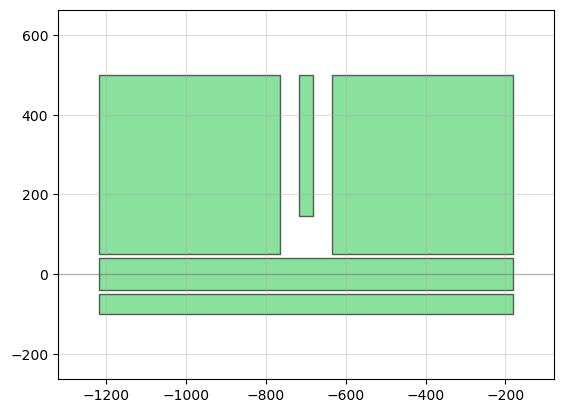

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


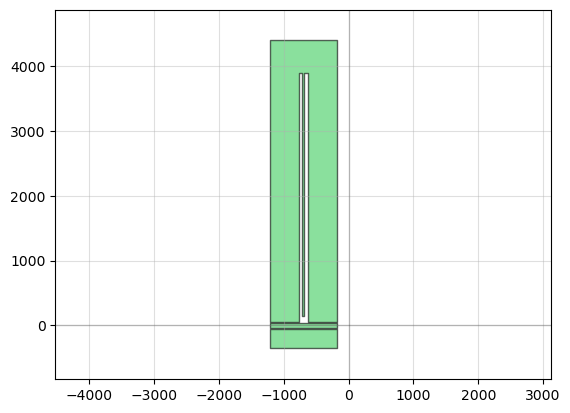

'11_04_26_lambda4_res_3750_um_36um_48um_105um.gds'

In [108]:
# resonator_params = [(30,18,8,2750,18),(50,22,16,2875,22),(60,26,24,2900,26),(90,30,32,5250,30),(120,34,40,5000,34)]

lambda_4_resonator_params = [(20,18,8,3000),(65,28,28,3600),(105,36,48,3750),(40,18,8,1800),(210,48,88,2650)]
lambda_2_resonator_params = [(135,42,68,7600),(175,48,88,7550)]

idx = 2
hammerhead_gap,center_pin_width,ground_plane_gap,center_pin_length = lambda_4_resonator_params[idx]
coupling_length = center_pin_width

res, res_outline = make_lamda4_res_straight(center_pin_length=center_pin_length,width=center_pin_width,center_pin_gap=ground_plane_gap,coupling_length=coupling_length,coupling_width = 1,hammerhead_gap=hammerhead_gap)

chip_layout = phidl.Device('chip_layout')

groundplane = pg.rectangle(size=(25e3,25e3))
groundplane_ref = chip_layout.add_ref(groundplane)
groundplane_ref.x=0
groundplane_ref.y=0

# Subtract the ground plane gaps.
feedline_ref = chip_layout.add_ref(feedline)
feedline_outline_ref = chip_layout.add_ref(feedline_outline)
chip_layout = pg.boolean(chip_layout,feedline_outline_ref,operation='A-B')
chip_layout = pg.boolean(chip_layout,feedline_ref,operation='A+B')

res_ref = chip_layout.add_ref(res)
res_outline_ref = chip_layout.add_ref(res_outline)
port = feedline.ports[1]

res_outline_ref.x = port.midpoint[0]
res_outline_ref.ymin = port.midpoint[1] 

res_ref.x = port.midpoint[0]
res_ref.ymin = port.midpoint[1] + hammerhead_gap

chip_layout = pg.boolean(chip_layout,res_outline_ref,operation='A-B')
chip_layout = pg.boolean(chip_layout,res_ref,operation='A+B')

b = res_ref.bbox
padding = 500
bbox = [
    [b[0][0] - padding, -100],  # xmin - pad, ymin - pad
    [b[1][0] + padding, 500]   # xmax + pad, ymax + pad
]
bbox = pg.bbox(bbox)
cutout = pg.boolean(bbox,chip_layout,operation='and')
qp(cutout)
cutout.write_gds(f'11_04_26_lambda4_coupling_{center_pin_length}_um_{center_pin_width}um_{ground_plane_gap}um_{hammerhead_gap}um.gds')

bbox = [
    [b[0][0] - padding, b[0][1] - padding],  # xmin - pad, ymin - pad
    [b[1][0] + padding, b[1][1] + padding]   # xmax + pad, ymax + pad
]
bbox = pg.bbox(bbox)
cutout = pg.boolean(bbox,chip_layout,operation='and')
qp(cutout)
cutout.write_gds(f'11_04_26_lambda4_res_{center_pin_length}_um_{center_pin_width}um_{ground_plane_gap}um_{hammerhead_gap}um.gds')